Billy York

06/26/26

# The Batch Cleaning and Enrichment Job

## Revised Schema


```sql
CREATE TABLE home_sale_event (
    lat NUMERIC NOT NULL,
    long NUMERIC NOT NULL,
    zipcode INTEGER NOT NULL,
    sqft_lot INTEGER NOT NULL CHECK (sqft_lot > 0 AND sqft_lot <= 500000),
    sqft_living INTEGER NOT NULL CHECK (sqft_living > 0 AND sqft_living <= 8000),
    sqft_above INTEGER NOT NULL CHECK (sqft_above > 0),
    sqft_basement INTEGER, --Removed NOT NULL--
    has_basement BOOLEAN GENERATED ALWAYS AS (sqft_basement > 0), --New Column--
    sqft_lot15 INTEGER NOT NULL CHECK (sqft_lot15 > 0 AND sqft_lot15 <= 200000),
    sqft_living15 INTEGER NOT NULL CHECK (sqft_living15 > 0 AND sqft_living <= 5000),
    yr_built INTEGER NOT NULL CHECK (yr_built >= 1900), --Add Check for yr_built--
    yr_renovated INTEGER, --Removed NOT NULL--
    was_renovated BOOLEAN GENERATED ALWAYS AS (yr_renovated > 0), --New Column-- 
    condition INTEGER NOT NULL CHECK (condition > 1),
    grade INTEGER NOT NULL CHECK (grade > 1),
    floors FLOAT NOT NULL CHECK (floors >= 1),
    bedrooms INTEGER NOT NULL CHECK ((bedrooms > 0 AND bedrooms <= 6) OR (bedrooms == 0 AND bathrooms >= 0.75)), --Add Check for Studios--
    bathrooms FLOAT NOT NULL CHECK (bathrooms >= 0.75 AND bathrooms <= 6), --Increase Lower Limit--
    view INTEGER NOT NULL,
    waterfront INTEGER NOT NULL CHECK (waterfront == 0 OR waterfront ==1),
    price NUMERIC NOT NULL CHECK (price > 0 AND price <= 4000000), --Add Check--
    event_timestamp DATETIME NOT NULL,
    economic_conditions NUMERIC NOT NULL, --INTEGER -> NUMERIC--
    id INTEGER PRIMARY KEY REFERENCES raw_home_sale_events(id), --Add foreign key reference--
);
```

## Plotting Number of Events Cleaned By Hour

In [1]:
from matplotlib import pyplot
import seaborn as sns
import pandas as pd
import psycopg
from psycopg.rows import dict_row

In [2]:
user = 'postgres'
password = 'psql-password'
host = '127.0.0.1'

In [3]:
conn_string = 'postgresql://{}:{}@{}:5432/house_price_prediction_service'.format(user, password, host)
with psycopg.connect(conn_string, row_factory=dict_row) as conn:
    with conn.cursor() as cur:
        cur.execute('SELECT * FROM cleaned_home_sale_events;')
        # rows will be a list of dicts with the keys 'id', 'event_timestamp', and 'data'
        rows = cur.fetchall()

In [4]:
df = pd.DataFrame.from_records(rows)
df.head()

,lat,long,zipcode,sqft_lot,sqft_living,sqft_above,sqft_basement,has_basement,sqft_lot15,sqft_living15,...,event_timestamp,economic_conditions,id,zipcode_population,zipcode_public_high_schools,zipcode_public_middle_schools,zipcode_public_primary_schools,zipcode_public_other_schools,zipcode_public_unknown_schools,zipcode_public_total_schools
0,47.6916,-122.341,98103,1448,1430,1430,0,False,1383,1430,...,2026-06-27 22:02:03.611797,1.0,79534,137733,1,1,6,0,0,8
1,47.5827,-122.387,98116,1904,1710,1140,570,True,1316,1260,...,2026-06-27 22:01:35.390825,1.0,79533,66723,1,1,4,0,0,6
2,47.4781,-122.294,98168,34133,750,750,0,False,25792,1460,...,2026-06-27 21:54:03.849353,1.0,79517,101202,1,1,7,0,0,9
3,47.3484,-122.033,98038,6000,1370,1370,0,False,6200,1370,...,2026-06-29 03:10:22.790142,1.0,83251,93513,0,2,4,1,0,7
4,47.6711,-122.148,98052,7700,1270,1270,0,False,7700,1510,...,2026-06-29 03:09:54.566853,1.0,83250,175326,3,3,8,1,0,15


In [5]:
grouped = df.groupby(df['event_timestamp'].dt.day)
days = grouped.groups.keys()
grouped = grouped.count()
grouped.head(10)

,lat,long,zipcode,sqft_lot,sqft_living,sqft_above,sqft_basement,has_basement,sqft_lot15,sqft_living15,...,event_timestamp,economic_conditions,id,zipcode_population,zipcode_public_high_schools,zipcode_public_middle_schools,zipcode_public_primary_schools,zipcode_public_other_schools,zipcode_public_unknown_schools,zipcode_public_total_schools
event_timestamp,,,,,,,,,,,,,,,,,,,,,
16,2728,2728,2728,2728,2728,2728,2728,2728,2728,2728,...,2728,2728,2728,2728,2728,2728,2728,2728,2728,2728
17,3017,3017,3017,3017,3017,3017,3017,3017,3017,3017,...,3017,3017,3017,3017,3017,3017,3017,3017,3017,3017
18,3001,3001,3001,3001,3001,3001,3001,3001,3001,3001,...,3001,3001,3001,3001,3001,3001,3001,3001,3001,3001
19,3010,3010,3010,3010,3010,3010,3010,3010,3010,3010,...,3010,3010,3010,3010,3010,3010,3010,3010,3010,3010
20,3011,3011,3011,3011,3011,3011,3011,3011,3011,3011,...,3011,3011,3011,3011,3011,3011,3011,3011,3011,3011
21,3021,3021,3021,3021,3021,3021,3021,3021,3021,3021,...,3021,3021,3021,3021,3021,3021,3021,3021,3021,3021
22,3022,3022,3022,3022,3022,3022,3022,3022,3022,3022,...,3022,3022,3022,3022,3022,3022,3022,3022,3022,3022
23,3027,3027,3027,3027,3027,3027,3027,3027,3027,3027,...,3027,3027,3027,3027,3027,3027,3027,3027,3027,3027
24,3017,3017,3017,3017,3017,3017,3017,3017,3017,3017,...,3017,3017,3017,3017,3017,3017,3017,3017,3017,3017


[Text(0.5, 1.0, 'Number of House Records Cleaned Each Hour'),
 Text(0.5, 0, 'Day of Event'),
 Text(0, 0.5, 'Number of Events Cleaned')]

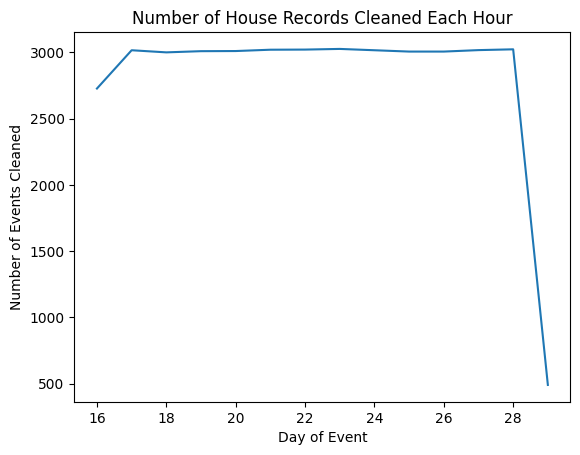

In [6]:
sns.lineplot(x=days, y=grouped['id']).set(title='Number of House Records Cleaned Each Hour', xlabel='Day of Event', ylabel='Number of Events Cleaned')

## Running Containers

![milestone3_1.png](milestone3_1.png)

## Table Schemas

![milestone3_2.png](milestone3_2.png)

![milestone3_3.png](milestone3_3.png)

![milestone3_4.png](milestone3_4.png)

![milestone3_5.png](milestone3_5.png)

![milestone3_6.png](milestone3_6.png)

## Sample Records

![milestone3_7.png](milestone3_7.png)

![milestone3_8.png](milestone3_8.png)